In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%pip install plotly
%pip install nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:

# Lê o arquivo original
df = pd.read_csv("results.csv")

# Agrupa por (n_cores, seed) e calcula a média de todas as colunas numéricas
df_avg = df.groupby(["n_cores", "seed"], as_index=False).mean()

# Salva o resultado ordenado
df_avg.sort_values(by=["n_cores", "seed"]).to_csv(
    "results_average.csv", index=False
)

print("Arquivo 'results_average.csv' gerado com sucesso via Pandas.")

Arquivo 'results_average.csv' gerado com sucesso via Pandas.


In [8]:
# 1. Carrega os dois arquivos CSV
df_raw = pd.read_csv("results.csv")
df_avg = pd.read_csv("results_average.csv")

# Identifica as colunas de tempo
time_cols = [c for c in df_raw.columns if c not in ["n_cores", "seed"]]

# 2. Une os dados das execuções individuais com as médias correspondentes
merged = pd.merge(
    df_raw, df_avg, on=["n_cores", "seed"], suffixes=("", "_avg")
)

# 3. Calcula o desvio relativo absoluto de cada execução em relação à média: |valor - média| / média
for col in time_cols:
    merged[col] = (
        merged[col] - merged[col + "_avg"]
    ).abs() / merged[col + "_avg"]

# 4. Calcula a média desses desvios relativos dentro de cada tupla (n_cores, seed)
df_rel_intra = merged.groupby(["n_cores", "seed"], as_index=False)[
    time_cols
].mean()

# 5. Ordena e salva o resultado final no arquivo solicitado
df_rel_intra.sort_values(by=["n_cores", "seed"]).to_csv(
    "results_mean_rel_intra.csv", index=False
)

print("Arquivo 'results_mean_rel_intra.csv' gerado com sucesso!")

Arquivo 'results_mean_rel_intra.csv' gerado com sucesso!


In [ ]:

import plotly.graph_objects as go

# 1. Carrega os dados
df_avg = pd.read_csv("results_average.csv")

# 2. Pivota para criar a matriz da superfície
pivot_df = df_avg.pivot(
    index="n_cores", columns="seed", values="time_2048_gen"
)

# 3. Cria a Superfície 3D
surface = go.Surface(
    x=pivot_df.columns,  # Eixo Seed
    y=pivot_df.index,  # Eixo n_cores
    z=pivot_df.values,  # Eixo Tempo
    colorscale="Viridis",
    opacity=0.75,
    name="Superfície",
)

# 4. Adiciona os Marcadores/Esferas dos Dados Reais
scatter = go.Scatter3d(
    x=df_avg["seed"],
    y=df_avg["n_cores"],
    z=df_avg["time_2048_gen"],
    mode="markers",
    marker=dict(
        size=7,
        color="red",
        symbol="circle",
        line=dict(color="black", width=1),
    ),
    name="Dados Reais",
    hovertemplate="<b>Seed:</b> %{x}<br><b>n_cores:</b> %{y}<br><b>Tempo:</b> %{z:.2f}s<extra></extra>",
)

# 5. Junta a superfície e as esferas na mesma figura
fig = go.Figure(data=[surface, scatter])

# 6. Personaliza eixos discretos e títulos
fig.update_layout(
    title="Superfície 3D de Tempo de Execução (2048 Gerações)",
    scene=dict(
        xaxis=dict(
            title=" x :Seed",
            tickmode="array",
            tickvals=sorted(df_avg["seed"].unique()),
        ),
        yaxis=dict(
            title=" y :Número de Cores (n_cores)",
            tickmode="array",
            tickvals=sorted(df_avg["n_cores"].unique()),
        ),
        zaxis=dict(title="z : Tempo (s)"),
    ),
    width=900,
    height=700,
)

# Exibe o gráfico interativo
fig.show()

   n_cores  time_2048_gen   speedup  eficiencia
0        1    4850.406895  1.000000    1.000000
1        2    1960.576872  2.473969    1.236985
2        4    1438.529044  3.371782    0.842946
3        8     877.428584  5.527979    0.690997
4       14     783.651496  6.189495    0.442107


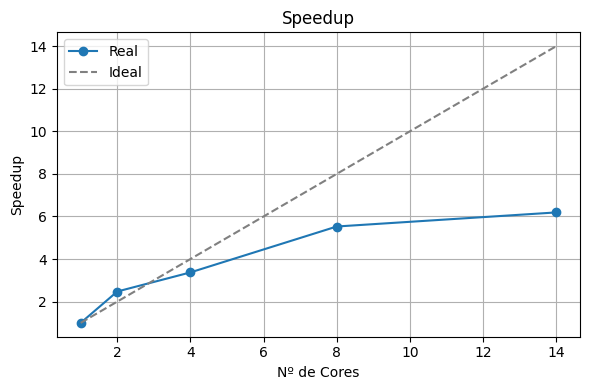

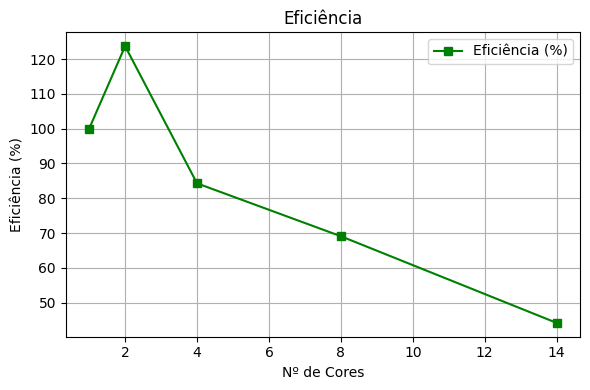

In [ ]:
import matplotlib.pyplot as plt

# 1. Carrega os dados e calcula a média de tempo para cada n_cores
df = pd.read_csv("results_average.csv")
df_cores = df.groupby("n_cores", as_index=False)["time_2048_gen"].mean()

# 2. Calcula Speedup e Eficiência
t1 = df_cores.loc[
    df_cores["n_cores"] == df_cores["n_cores"].min(), "time_2048_gen"
].values[0]
df_cores["speedup"] = t1 / df_cores["time_2048_gen"]
df_cores["eficiencia"] = df_cores["speedup"] / df_cores["n_cores"]

# 3. Exibe e salva a tabela
print(df_cores[["n_cores", "time_2048_gen", "speedup", "eficiencia"]])
df_cores.to_csv("tabela_speedup_eficiencia.csv", index=False)

# ---------------------------------------------------------
# Figura 1: Speedup
# ---------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(df_cores["n_cores"], df_cores["speedup"], "o-", label="Real")
plt.plot(
    df_cores["n_cores"],
    df_cores["n_cores"],
    "--",
    color="gray",
    label="Ideal",
)
plt.xlabel("Nº de Cores")
plt.ylabel("Speedup")
plt.title("Speedup")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Figura 2: Eficiência
# ---------------------------------------------------------
plt.figure(figsize=(6, 4))
plt.plot(
    df_cores["n_cores"],
    df_cores["eficiencia"] * 100,
    "s-",
    color="green",
    label="Eficiência (%)",
)
plt.xlabel("Nº de Cores")
plt.ylabel("Eficiência (%)")
plt.title("Eficiência")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()